# Finding the best learning rate

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
plt.style.use('ggplot')
plt.rcParams['figure.dpi'] = 100

In [71]:
from sklearn.datasets import make_circles
X, y = make_circles(n_samples = 1000, 
                    noise=0.03, 
                    random_state=42)

In [72]:
X_train, y_train = X[:800], y[:800] 
X_test, y_test = X[800:], y[800:] 

In [73]:
# Set random seed
tf.random.set_seed(42)

# Create a model (same as model_8)
model_9 = tf.keras.Sequential([
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model
model_9.compile(loss="binary_crossentropy", # we can use strings here too
              optimizer="Adam", # same as tf.keras.optimizers.Adam() with default settings
              metrics=["accuracy"]) 

# Create a learning rate scheduler callback
 # traverse a set of learning rate values starting from 1e-4, increasing by 10^(epoch/20) every epoch
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(lambda epoch: 1e-4 * 10**(epoch/20))

# Fit the model (passing the lr_scheduler callback)
history = model_9.fit(X_train, 
                      y_train, 
                      epochs=100,
                      callbacks=[lr_scheduler])

Epoch 1/100
25/25 [==============================] - 0s 1ms/step - loss: 0.6945 - accuracy: 0.4988 - lr: 1.0000e-04
Epoch 2/100
25/25 [==============================] - 0s 2ms/step - loss: 0.6938 - accuracy: 0.4975 - lr: 1.1220e-04
Epoch 3/100
25/25 [==============================] - 0s 2ms/step - loss: 0.6930 - accuracy: 0.4963 - lr: 1.2589e-04
Epoch 4/100
25/25 [==============================] - 0s 2ms/step - loss: 0.6922 - accuracy: 0.4975 - lr: 1.4125e-04
Epoch 5/100
25/25 [==============================] - 0s 3ms/step - loss: 0.6914 - accuracy: 0.5063 - lr: 1.5849e-04
Epoch 6/100
25/25 [==============================] - 0s 2ms/step - loss: 0.6906 - accuracy: 0.5013 - lr: 1.7783e-04
Epoch 7/100
25/25 [==============================] - 0s 2ms/step - loss: 0.6898 - accuracy: 0.4950 - lr: 1.9953e-04
Epoch 8/100
25/25 [==============================] - 0s 2ms/step - loss: 0.6889 - accuracy: 0.5038 - lr: 2.2387e-04
Epoch 9/100
25/25 [==============================] - 0s 2ms/step - loss:

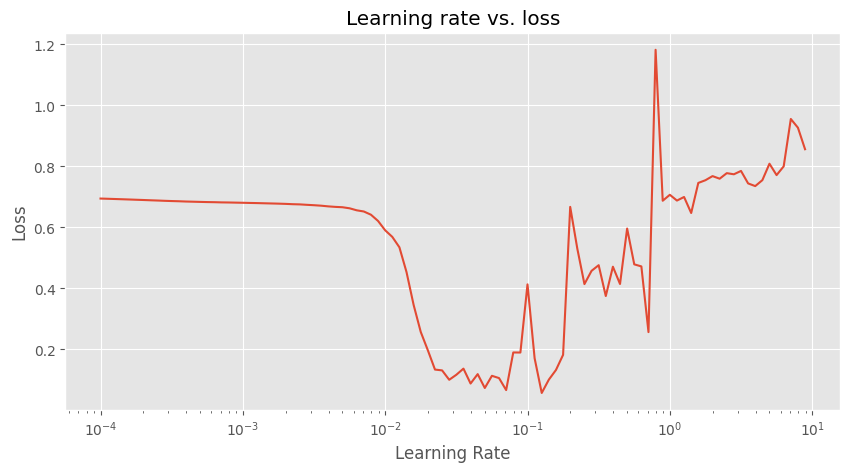

In [74]:
lrs = 1e-4 * (10 ** (np.arange(100)/20))
plt.figure(figsize=(10, 5))
plt.semilogx(lrs, history.history["loss"]) # we want the x-axis (learning rate) to be log scale
plt.xlabel("Learning Rate")
plt.ylabel("Loss")
plt.title("Learning rate vs. loss");

7/7 [==============================] - 0s 2ms/step - loss: 0.6932 - accuracy: 0.4950


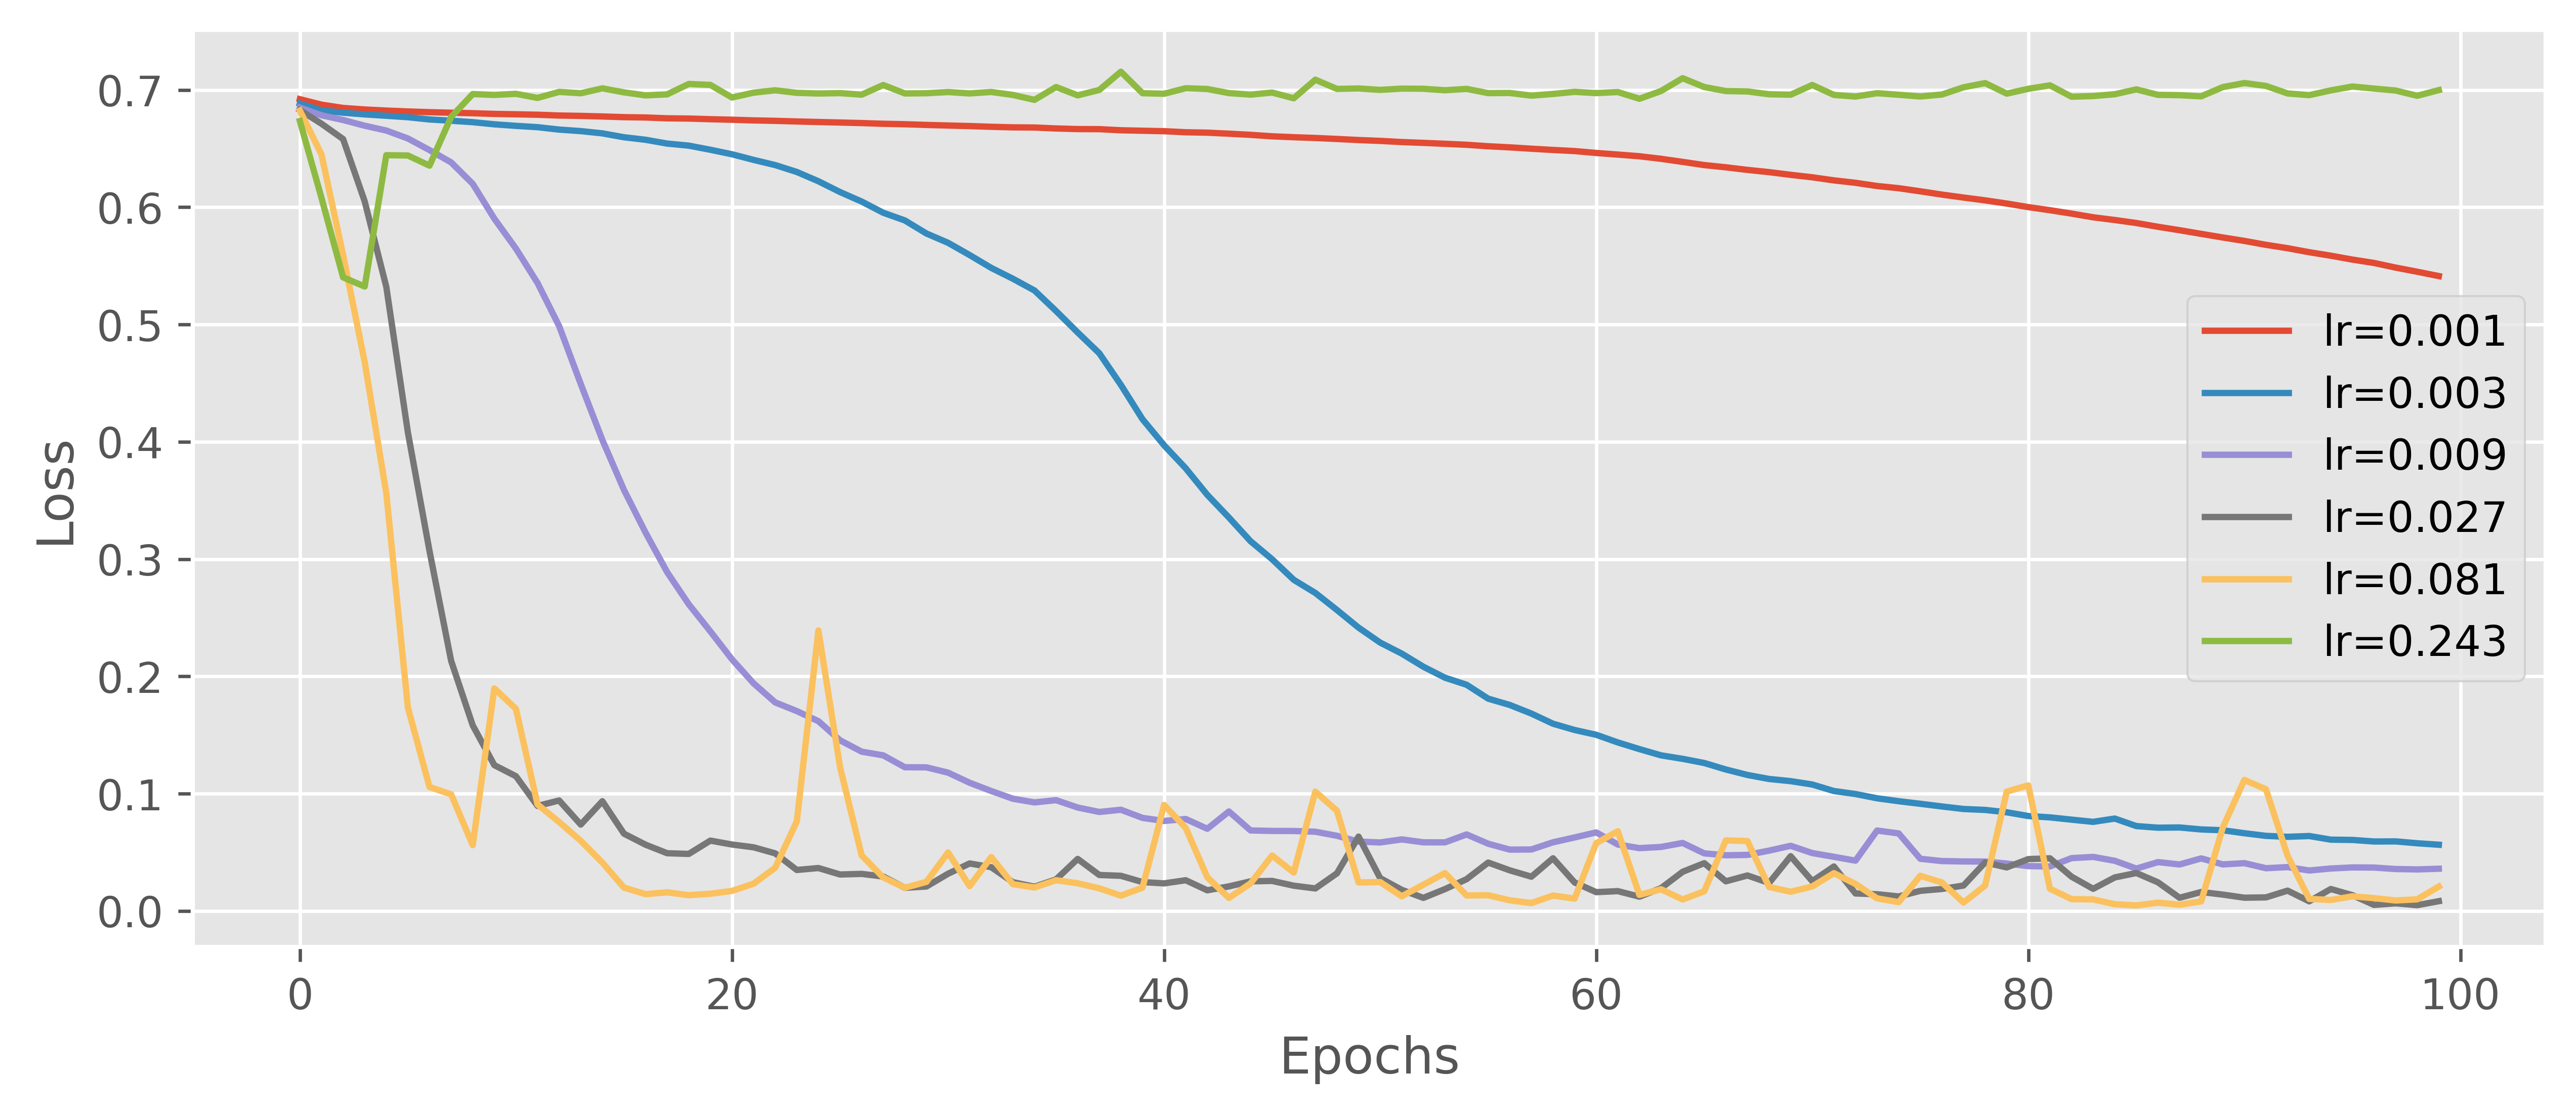

In [132]:
nnn = 6
test = np.ones(nnn)
l_ra = test
plt.figure(figsize=(10, 4), dpi=600)
for ii in range (0, nnn, 1):
    tf.random.set_seed(42)

    model_9 = tf.keras.Sequential([
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    lr_rate = np.round(0.001*3**ii, 4)
    model_9.compile(loss="binary_crossentropy", # we can use strings here too
                optimizer=tf.keras.optimizers.Adam(learning_rate=lr_rate),
                metrics=["accuracy"]) 

    history = model_9.fit(X_train, y_train, epochs=100, verbose=0)
    hist_test = model_9.evaluate(X_test, y_test)
    test[ii] = hist_test[0]
    l_ra[ii] = lr_rate

    y = pd.DataFrame(history.history['loss'])
    y = pd.DataFrame.to_numpy(y).T[0]
    x = np.arange(len(y))
    plt.plot(x,y, label="lr="+str(lr_rate))

plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

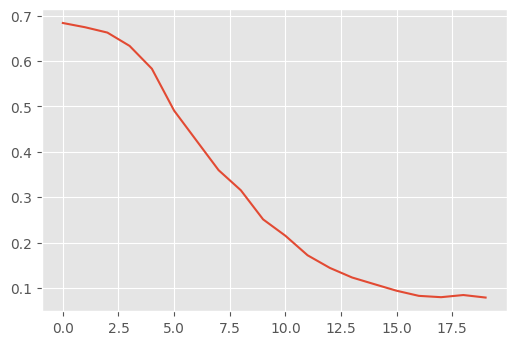

In [148]:
tf.random.set_seed(42)

model_10 = tf.keras.Sequential([
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
    ])

lr_rate =0.02
model_10.compile(loss="binary_crossentropy", # we can use strings here too
                optimizer=tf.keras.optimizers.Adam(learning_rate=lr_rate),
                metrics=["accuracy"]) 

history = model_10.fit(X_train, y_train, epochs=20, verbose=0)


y = pd.DataFrame(history.history['loss'])
y = pd.DataFrame.to_numpy(y).T[0]
x = np.arange(len(y))
plt.plot(x,y, label="lr="+str(lr_rate))

In [181]:
# Create a confusion matrix
y_preds = model_10.predict(X_test)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, tf.round(y_preds))
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
n_classes = cm.shape[0]
cm

array([[99,  2],
       [ 0, 99]])

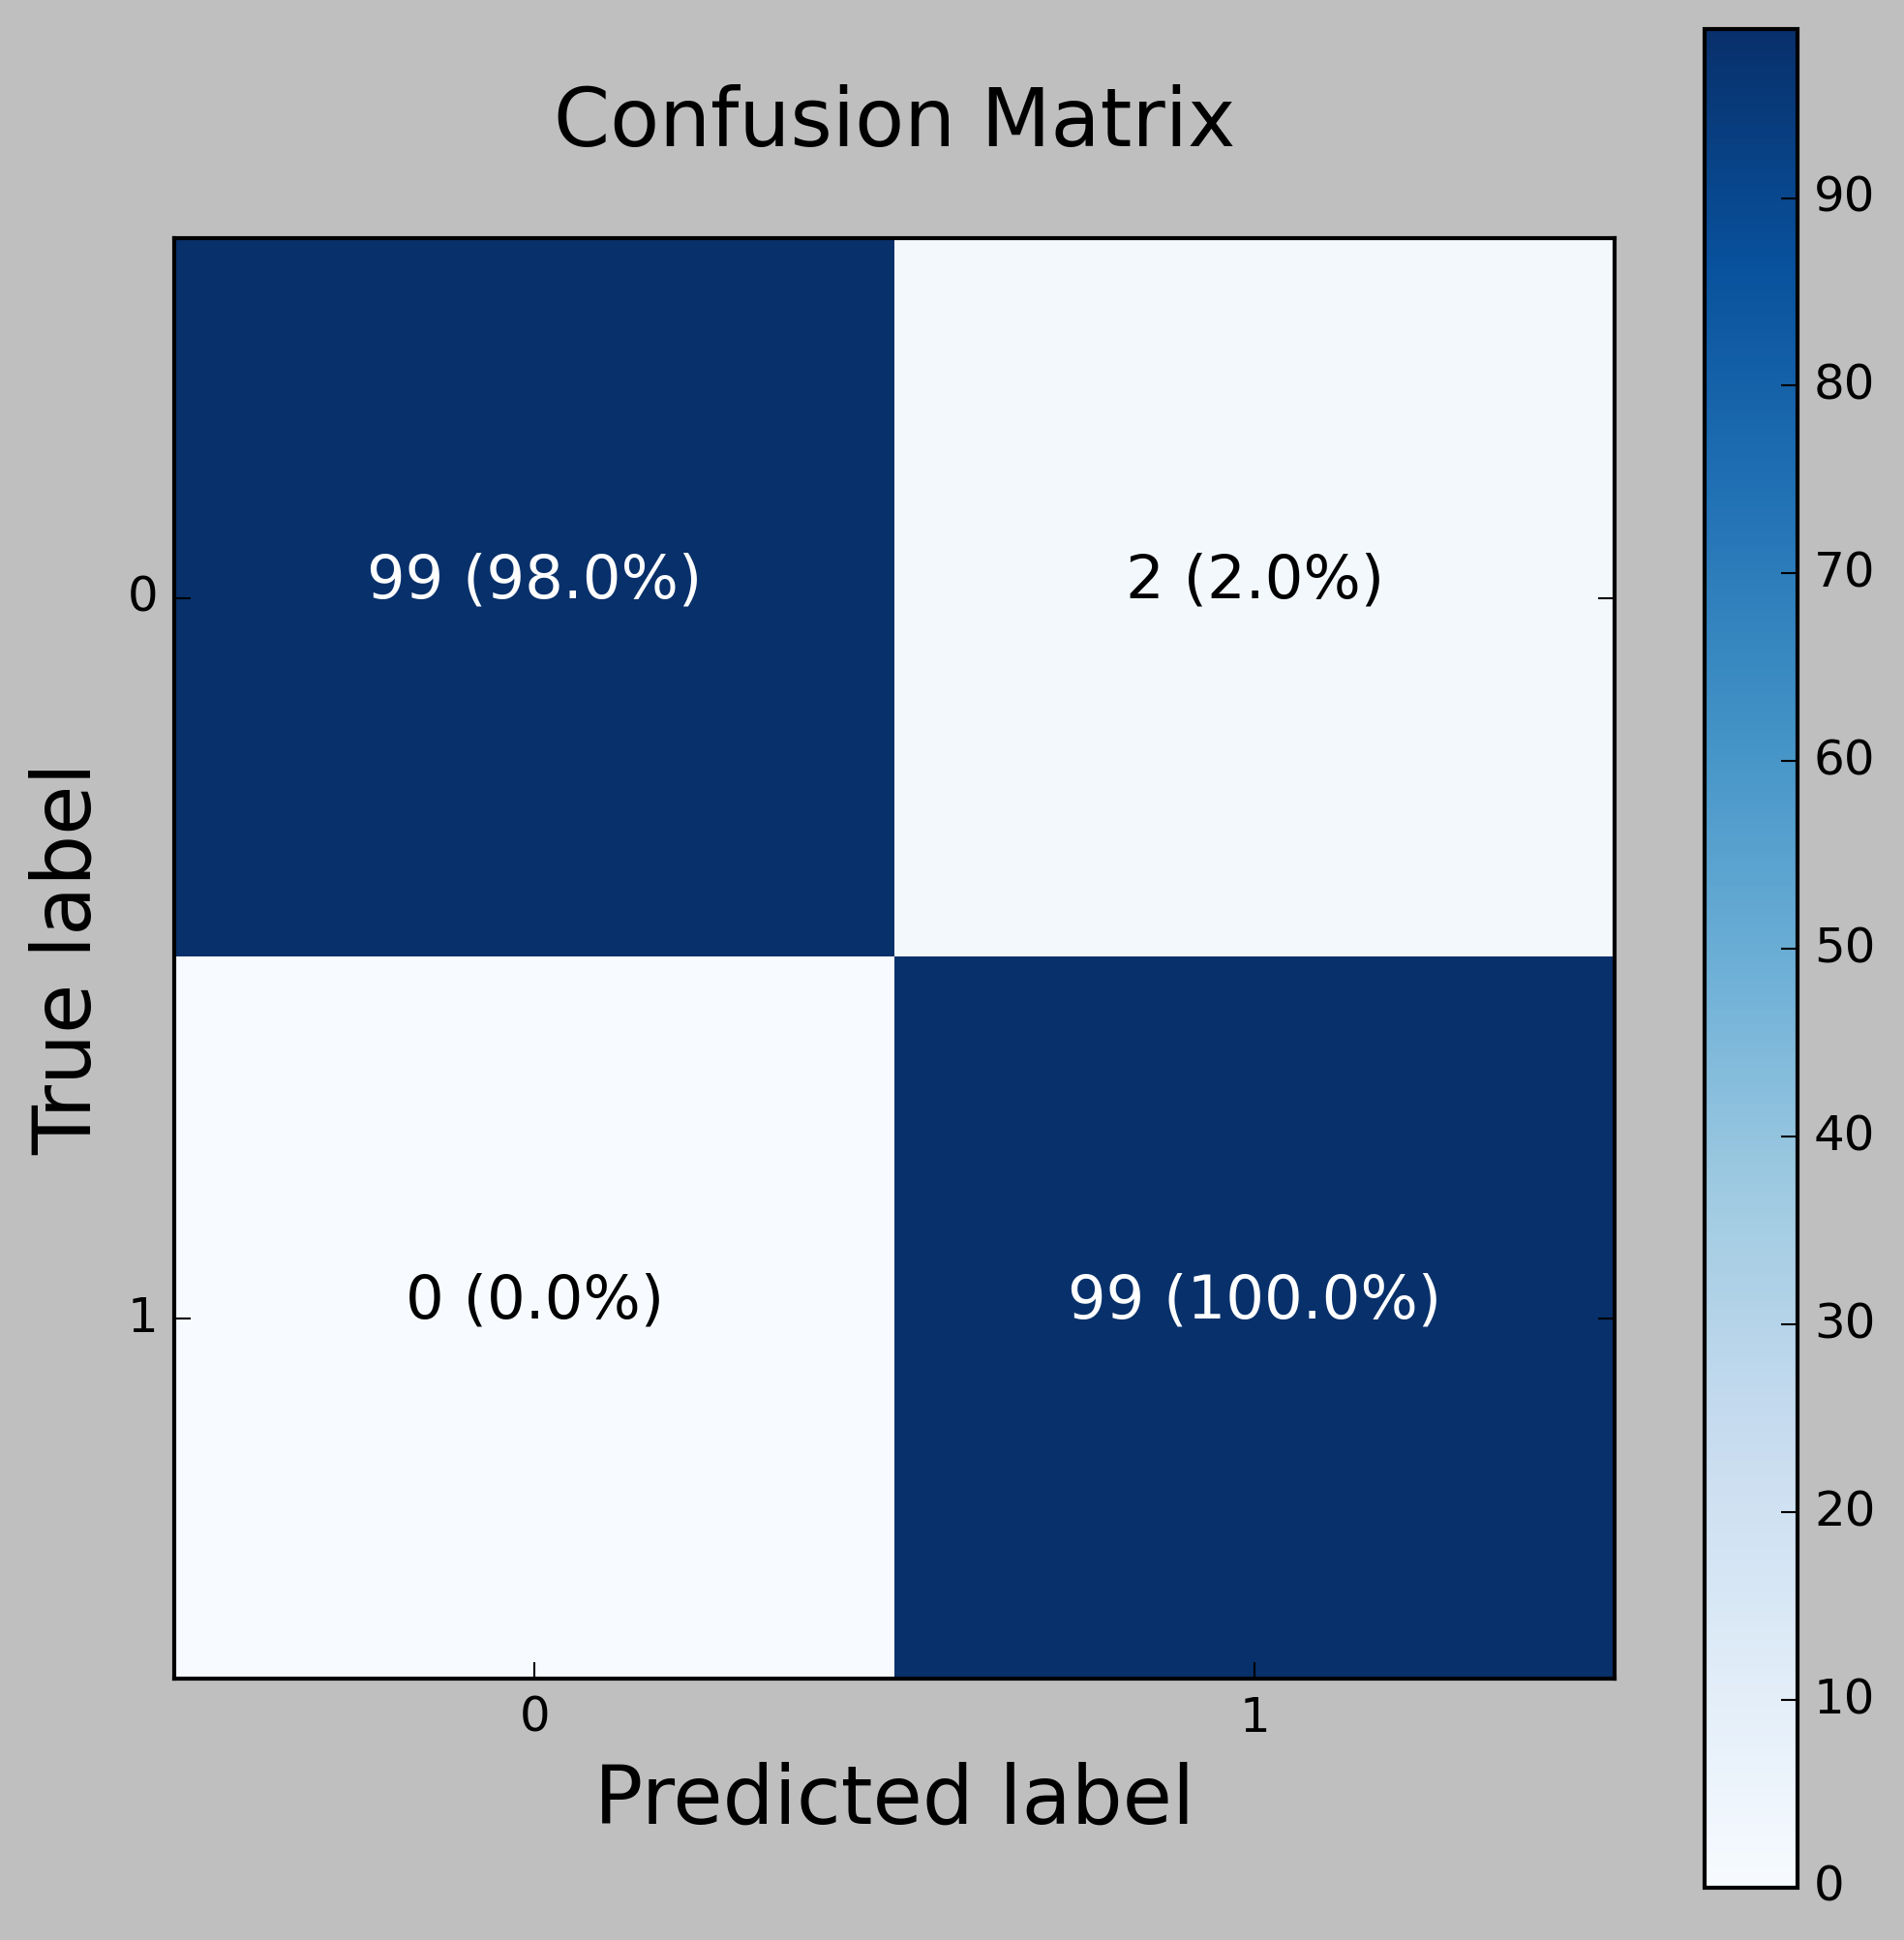

In [182]:
plt.style.use('fast')
import itertools
fig, ax = plt.subplots(figsize=(8,8), dpi=300)
cax = ax.matshow(cm, cmap=plt.cm.Blues)
fig.colorbar(cax)

# Create classes
classes = False

if classes:
  labels = classes
else:
  labels = np.arange(cm.shape[0])

# Label the axes
ax.set(title="Confusion Matrix",
       xlabel="Predicted label",
       ylabel="True label",
       xticks=np.arange(n_classes),
       yticks=np.arange(n_classes),
       xticklabels=labels,
       yticklabels=labels)

# Set x-axis labels to bottom
ax.xaxis.set_label_position("bottom")
ax.xaxis.tick_bottom()

# Adjust label size
ax.xaxis.label.set_size(20)
ax.yaxis.label.set_size(20)
ax.title.set_size(20)

# Set threshold for different colors
threshold = (cm.max() + cm.min()) / 2.

# Plot the text on each cell
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
  plt.text(j, i, f"{cm[i, j]} ({cm_norm[i, j]*100:.1f}%)",
           horizontalalignment="center",
           color="white" if cm[i, j] > threshold else "black",
           size=15)

In [153]:
cm

array([[99,  2],
       [ 0, 99]])

array([[101],
       [ 99]])

In [ ]:
import itertools
figsize = (10, 10)
cm = confusion_matrix(y_test, tf.round(y_preds))
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] # normalize it
n_classes = cm.shape[0]